## DRQN with LSTM: Droplet Protocol Tracing and Reverse Engineering

This notebook implements a Deep Recurrent Q-Network (DRQN) with support for LSTM architectures for reverse-engineering droplet protocols on DMFBs. 

### Key Features:
- **LSTM**: Traditional recurrent memory for short-term dependencies
- **Episode-based replay**: Stores complete episodes for sequential learning
 
### Architecture Options:
1. **LSTM (Default)**: Fast, baseline with 256 hidden units

### References

```bibtex
@misc{hausknecht2017deeprecurrentqlearningpartially,
  title={Deep Recurrent Q-Learning for Partially Observable MDPs},
  author={Matthew Hausknecht and Peter Stone},
  year={2017},
  eprint={1507.06527},
  archivePrefix={arXiv},
  primaryClass={cs.LG},
  url={https://arxiv.org/abs/1507.06527},
}


## Import necessary libraries 

In [1]:
# importing necessary libraries
import random
import time
import os 
import numpy as np
import torch
import torch.nn as nn
from collections import deque
from torch.utils.tensorboard import SummaryWriter
from tqdm import tqdm
import pickle
import json 
import matplotlib.pyplot as plt


## DRQN Agent with LSTM Support

**DRQNagent** is an implementation of DRQN supporting both LSTM and GTrXL architectures.

### Architecture
- **Feature Extractor** → **LSTM** → **Fully-Connected Q-value Head**
- LSTM: 256 hidden units (default)

### Key Components
1. **Replay Buffer**: Episode-based storage (complete sequences)
2. **Network**: LSTM based network
3. **Training**: Standard DQN with episode sampling and target network updates

In [2]:
# Import custom environment and feature extractor
from Env import VoltageDistributionEnv
from CustomFeatureExtractor import CustomFeatureExtractor

class DRQNagent:

    """
    Simplified Deep Recurrent Q-Network:
    - Store complete episodes in replay buffer
    - Train LSTM on full episode sequences
    - save trained agent as .zip file to desktop 
    - action_masking based on belief state map 
    """
    
    def __init__(self, 
                 env,                       
                 feature_extractor, 
                 action_dim, 
                 lstm_hidden_size=256,
                 gamma=0.99, 
                 lr=1e-4, 
                 batch_size=32, 
                 buffer_size=1000,
                 epsilon_start=1.0, 
                 epsilon_end=0.05, 
                 epsilon_decay=5000,
                 target_update=500, 
                 training_steps=10_000, 
                 tensorboard_dir=None,
                 run_name=None,
                 action_mask = False):
        
        self.env = env()
        self.feature_extractor_fn = feature_extractor
        self.action_dim = action_dim
        self.lstm_hidden_size = lstm_hidden_size
        self.gamma = gamma
        self.lr = lr
        self.batch_size = batch_size
        self.buffer_size = buffer_size
        self.epsilon_start = epsilon_start
        self.epsilon_end = epsilon_end
        self.epsilon_decay = epsilon_decay
        self.target_update = target_update
        self.training_steps = training_steps
        self.action_mask = action_mask
        
        # running on CPU (current device is a macbook, change if needed)
        self.device = torch.device('cpu')

        # TensorBoard writer, save the train data to a chosen name (opens a folder)
        if tensorboard_dir and run_name:
            log_dir = os.path.join(tensorboard_dir, run_name)
            self.writer = SummaryWriter(log_dir=log_dir)
            print(f"TensorBoard logging to: {log_dir}")
        elif tensorboard_dir:
            self.writer = SummaryWriter(log_dir=tensorboard_dir)
            print(f"TensorBoard logging to: {tensorboard_dir}")
        else:
            self.writer = None

        # feature extractor network 
        feature_extractor = feature_extractor(self.env.observation_space)
        feat_dim = feature_extractor._features_dim
        
        # target and online networks 
        self.online_net = self._build_network(feature_extractor, feat_dim, lstm_hidden_size, action_dim)                                        # online network, trained through GD
        self.target_net = self._build_network(self.feature_extractor_fn(self.env.observation_space), feat_dim, lstm_hidden_size, action_dim)    # target network
        self.target_net.load_state_dict(self.online_net.state_dict())                                                                           # copies weights/biases from online to target
        self.target_net.eval()
        
        self.optimizer = torch.optim.Adam(self.online_net.parameters(), lr=lr)
        
        # Episode replay buffer - stores complete episodes
        self.replay_buffer = deque(maxlen=buffer_size)
        
        self.step_count = 0
        self.update_count = 0
        self.episode_count = 0
        
    def _build_network(self, feat_extractor, feat_dim, hidden_size, action_dim):

        class DRQNNet(nn.Module):

            """
            Creating network for DRQN
            """

            def __init__(
                    self, 
                    feat_extractor,
                    feat_dim, 
                    hidden_size, 
                    action_dim):
                
                super().__init__()


                self.feat_extractor = feat_extractor                                # extraction layer, CNN + MLP
                self.lstm = nn.LSTM(feat_dim, hidden_size, batch_first=True)        # recurrency layer
                self.fc = nn.Sequential(                                            # Q - Net
                    nn.Linear(hidden_size, 256),
                    nn.ReLU(),
                    nn.Linear(256, action_dim)
                )

            
            def forward(self, obs_dict, hidden=None):
                # obs_dict: {key: (batch, seq_len, ...)}
                B = obs_dict[list(obs_dict.keys())[0]].shape[0]
                T = obs_dict[list(obs_dict.keys())[0]].shape[1]
                
                # Flatten to (B*T, ...)
                flat_obs = {k: v.reshape(B*T, *v.shape[2:]) for k, v in obs_dict.items()}
                features = self.feat_extractor(flat_obs)                 # (B*T, feat_dim)
                features = features.view(B, T, -1)                       # (B, T, feat_dim)
                
                lstm_out, hidden = self.lstm(features, hidden)           # (B, T, hidden_size)
                q_values = self.fc(lstm_out)                             # (B, T, action_dim)

                return q_values, hidden
        
        return DRQNNet(feat_extractor, feat_dim, hidden_size, action_dim)
    
    def get_epsilon(self):
        return self.epsilon_end + (self.epsilon_start - self.epsilon_end) * np.exp(-self.step_count / self.epsilon_decay) # epsilon decay over time steps 
    
    def select_action(self, obs_dict, info, hidden, epsilon):
        """
        Epsilon-greedy action selection, with optional action masking
        """
        # get action mask from info dict if available 
        mask = None 
        if self.action_mask: 
            mask = info.get("action_mask", None)
        
        # epsilon action selection
        if random.random() < epsilon: 
            if mask is None: 
                action = self.env.action_space.sample() 
            else: 
                valid_actions = np.where(np.array(mask) == 1)[0] 
                action = np.random.choice(valid_actions) 
            return action, hidden

        # greedy action selection
        with torch.no_grad():
            obs_batch = {k: torch.from_numpy(v).unsqueeze(0).unsqueeze(0).float().to(self.device) for k, v in obs_dict.items()}
            q_vals, new_hidden = self.online_net(obs_batch, hidden)
            q_vals = q_vals.squeeze(0).squeeze(0)

            if mask is not None:
                mask_tensor = torch.from_numpy(mask).to(self.device)
                q_vals = q_vals.masked_fill(mask_tensor == 0, -1e9)
            action = q_vals.argmax().item()

        return action, new_hidden

    def store_episode(self, episode):

        """Store complete episode: list of (obs, action, reward, next_obs, done)"""

        self.replay_buffer.append(episode)
    
    def sample_batch(self):
        if len(self.replay_buffer) < self.batch_size:
            return None
        
        # Sample random episodes
        episodes = random.sample(self.replay_buffer, self.batch_size)

        return episodes
    
    def train_step(self):

        batch = self.sample_batch()
        if batch is None:
            return None
        
        total_loss = 0
        
        for episode in batch:
          
            obs_seq = []
            action_seq = []
            reward_seq = []
            next_obs_seq = []
            done_seq = []
            mask_seq = [] 

            for transition in episode:
                
                # support both action masking and non-masking transitions
                if len(transition) == 6:
                    obs, action, reward, next_obs, done, info = transition
                    mask_seq.append(info.get("action_mask", None))
                else:
                    obs, action, reward, next_obs, done = transition
                    mask_seq.append(None)
                
                obs_seq.append(obs)
                action_seq.append(action)
                reward_seq.append(reward)
                next_obs_seq.append(next_obs)
                done_seq.append(done)
            
            # Convert to tensors - shape: (1, T, ...)
            obs_batch = {k: torch.from_numpy(np.stack([o[k] for o in obs_seq])).unsqueeze(0).float().to(self.device)
                        for k in obs_seq[0].keys()}
            next_obs_batch = {k: torch.from_numpy(np.stack([o[k] for o in next_obs_seq])).unsqueeze(0).float().to(self.device)
                             for k in next_obs_seq[0].keys()}
            
            actions = torch.LongTensor(action_seq).unsqueeze(0).to(self.device)     # (1, T)
            rewards = torch.FloatTensor(reward_seq).unsqueeze(0).to(self.device)    # (1, T)
            dones = torch.FloatTensor(done_seq).unsqueeze(0).to(self.device)        # (1, T)
            

            hidden = None

            # Forward pass - current state Q-values
            q_values, hidden = self.online_net(obs_batch, hidden)        # (1, T, action_dim)
            q_values = q_values.squeeze(0)                  # (T, action_dim)
            current_q = q_values.gather(1, actions.squeeze(0).unsqueeze(1)).squeeze(1)  # (T,)

            # Compute target Q-values using next states
            with torch.no_grad():
                target_hidden = None
                next_q_values, target_hidden = self.target_net(next_obs_batch, target_hidden)          # (1, T, action_dim)
                next_q_values = next_q_values.squeeze(0)                    # (T, action_dim)
                
                if self.action_mask:
                    # Ensure all masks are present
                    assert all(m is not None for m in mask_seq), "Missing next-state action mask"
                    mask_tensor = torch.from_numpy(np.stack(mask_seq)).to(self.device)  # (T, action_dim)
                    next_q_values = next_q_values.masked_fill(mask_tensor == 0, -1e9)
                
                max_next_q = next_q_values.max(dim=1)[0]                    # (T,)
                target_q = rewards.squeeze(0) + self.gamma * max_next_q * (1 - dones.squeeze(0))
            
            # Loss
            loss = nn.functional.mse_loss(current_q, target_q)
            total_loss += loss.item()
            
            self.optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(self.online_net.parameters(), 1.0)
            self.optimizer.step()
        
        return total_loss / len(batch)
    
    def train(self):
        
        # Track rolling average for smoother logging
        episode_return_window = deque(maxlen=100)
        episode_normalized_return_window = deque(maxlen=100)

        
        # progress bar 
        with tqdm(total=self.training_steps, desc="Training Progress", unit="step") as pbar:

            print("\n ________________________________ training DRQN agent _________________________________\n")

            while self.step_count < self.training_steps:

                # Collect one episode
                obs, _ = self.env.reset()
                done = False
                info = {}
                episode = []
                episode_return = 0
                hidden = None
                episode_steps = 0
                
                while not done:
                    epsilon = self.get_epsilon()
                    action, hidden = self.select_action(obs, info, hidden, epsilon)
                    next_obs, reward, terminated, truncated, info = self.env.step(action)
                    done = terminated or truncated
                    
                    # Store transition 
                    episode.append((obs, action, reward, next_obs, done, info) if self.action_mask else (obs, action, reward, next_obs, done))
                    episode_return += reward
                    obs = next_obs
                    self.step_count += 1
                    episode_steps += 1

                pbar.update(episode_steps)

                # Store episode
                self.store_episode(episode)
                self.episode_count += 1
                episode_return_window.append(episode_return)
                
                normalized_return = episode_return / episode_steps if episode_steps > 0 else 0
                episode_normalized_return_window.append(normalized_return)

                # Log to TensorBoard
                if self.writer:
                    self.writer.add_scalar('rollout/ep_rew_mean', np.mean(episode_return_window), self.step_count)
                    self.writer.add_scalar('rollout/ep_len_mean', episode_steps, self.step_count)
                    self.writer.add_scalar('rollout/epsilon', epsilon, self.step_count)
                    self.writer.add_scalar('train/episode_reward', episode_return, self.episode_count)
                    self.writer.add_scalar('rollout/normalized_return', normalized_return, self.episode_count)
                    self.writer.add_scalar('rollout/normalized_return_mean', np.mean(episode_normalized_return_window), self.step_count)
                
                # Train
                loss = None
                if len(self.replay_buffer) >= self.batch_size:
                    loss = self.train_step()
                    self.update_count += 1
                    
                    # Log training metrics
                    if self.writer and loss is not None:
                        self.writer.add_scalar('train/loss', loss, self.update_count)
                    
                    # Update target network
                    if self.update_count % self.target_update == 0:
                        self.target_net.load_state_dict(self.online_net.state_dict())
        
        # Close TensorBoard writer
        if self.writer:
            log_dir = self.writer.log_dir
            self.writer.close()
            print(f"\nTensorBoard logs saved to: {log_dir}")
            print(f"To view: tensorboard --logdir={log_dir}")
        
        print("________________ training complete _________________ \n")
    
    def save_complete(self, filepath):
        """
        Save complete agent (SB3-style) - can reconstruct from scratch
        Saves to .pkl file containing everything needed to rebuild agent
        """

        save_dict = {
            # Model weights
            'online_net_state_dict': self.online_net.state_dict(),
            'target_net_state_dict': self.target_net.state_dict(),
            'optimizer_state_dict': self.optimizer.state_dict(),
            
            # Training state
            'step_count': self.step_count,
            'episode_count': self.episode_count,
            'update_count': self.update_count,
            
            # Complete hyperparameters 
            'init_params': {
                'action_dim': self.action_dim,
                'lstm_hidden_size': self.lstm_hidden_size,
                'gamma': self.gamma,
                'lr': self.lr,
                'batch_size': self.batch_size,
                'buffer_size': self.buffer_size,
                'epsilon_start': self.epsilon_start,
                'epsilon_end': self.epsilon_end,
                'epsilon_decay': self.epsilon_decay,
                'target_update': self.target_update,
                'training_steps': self.training_steps,
            },
        }
        
        # Change extension to .pkl for complete save
        if not filepath.endswith('.pkl'):
            filepath = filepath.replace('.pth', '.pkl')
        
        os.makedirs(os.path.dirname(filepath), exist_ok=True)
        
        with open(filepath, 'wb') as f:
            pickle.dump(save_dict, f)
        
        print(f"Complete agent saved to: {filepath}")
        print(f"File contains all hyperparameters - can reconstruct agent from scratch")
    
    @classmethod
    def load_complete(cls, filepath, env_constructor, feature_extractor_constructor):
        """
        Load complete agent (SB3-style) - reconstructs from saved hyperparameters
        
        Args:
            filepath: Path to .pkl file
            env_constructor: Environment constructor (lambda: YourEnv())
            feature_extractor_constructor: Feature extractor constructor (lambda obs_space: CustomFeatureExtractor(obs_space))
        
        Returns:
            Loaded agent instance
        """
        
        with open(filepath, 'rb') as f:
            save_dict = pickle.load(f)
        
        # Reconstruct agent with saved hyperparameters
        init_params = save_dict['init_params']
        agent = cls(
            env=env_constructor,
            feature_extractor=feature_extractor_constructor,
            **init_params  # saved hyperparameters used
        )
        
        # Load weights and training state
        agent.online_net.load_state_dict(save_dict['online_net_state_dict'])
        agent.target_net.load_state_dict(save_dict['target_net_state_dict'])
        agent.optimizer.load_state_dict(save_dict['optimizer_state_dict'])
        agent.step_count = save_dict['step_count']
        agent.episode_count = save_dict['episode_count']
        agent.update_count = save_dict['update_count']
        
        print(f"Complete agent loaded from: {filepath}")
        print(f"Trained for {agent.step_count} steps, {agent.episode_count} episodes")

        return agent

/Users/biplovebaral/Desktop/research/Droplet_Tracker_Modularized/official_repo/RRDQNvenv/lib/python3.12/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


## Train Agent

Train agent with own hyperparameters:

**TensorBoard Logging:**
- `rollout/ep_rew_mean`: Average episode reward (last 100)
- `rollout/ep_len_mean`: Average episode length (last 100)
- `rollout/normalized_return`: Reward per step (per episode)
- `rollout/normalized_return_mean`: Average normalized return (last 100)
- `rollout/epsilon`: Exploration rate
- `train/loss`: TD loss
- `train/episode_reward`: Current episode reward

**Run TensorBoard:** `tensorboard --logdir models/tensorboard`

In [3]:
# Get action space dimension
env_instance = VoltageDistributionEnv()
action_dim = env_instance.action_space.n
print(f"The total action dimensions are: {action_dim}")

The total action dimensions are: 70


### Option 1: Train LSTM Agent

Traditional recurrent architecture with n hidden units. 

In [5]:
LSTMagent = DRQNagent(
    # Environment and Architecture
    env=lambda: VoltageDistributionEnv(),                              # create environment instance
    feature_extractor=lambda obs_space: CustomFeatureExtractor(obs_space),  # feature extractor 
    action_dim = action_dim,                                                    # Number of discrete actions (N x N grid) 
    lstm_hidden_size=256,                                              # LSTM hidden state dimension (memory capacity)
    
    # Training Hyperparameters
    gamma=0.9,                                                        # Discount factor (how much to value future rewards)
    lr=1e-4,                                                           # Learning rate for Adam optimizer
    batch_size=32,                                                     # Number of episodes sampled per training update
    buffer_size=1_000,                                                # Replay buffer capacity (max episodes stored)
    
    # Exploration Strategy (Epsilon-Greedy)
    epsilon_start=1.0,                                                 # Initial exploration rate (100% random actions)
    epsilon_end=0.001,                                                 # Final exploration rate (n% random, n% greedy)
    epsilon_decay=5_000,                                               # Steps over which epsilon decays exponentially
    
    # Network Updates
    target_update=500,                                                 # Frequency (in updates) to sync target network with online network
    
    # Training Schedule
    training_steps=100_000,                                             # Total environment steps to train 
    
    # TensorBoard Logging
    tensorboard_dir='models/tensorboard',                             # Root directory for all TensorBoard logs
    run_name='DRQN_actionmask',                                       # Unique run identifier (creates subfolder for this experiment)

    # action masking
    action_mask=True                                                  # Enable action masking 
)

LSTMagent.train()
LSTMagent.save_complete('models/DRQN_actionmask.pkl')

TensorBoard logging to: models/tensorboard/DRQN_actionmask


Training Progress:   0%|          | 159/100000 [00:00<01:03, 1566.54step/s]


 ________________________________ training DRQN agent _________________________________



Training Progress: 100003step [50:51, 32.78step/s]                           


TensorBoard logs saved to: models/tensorboard/DRQN_actionmask
To view: tensorboard --logdir=models/tensorboard/DRQN_actionmask
________________ training complete _________________ 

Complete agent saved to: models/DRQN_actionmask.pkl
File contains all hyperparameters - can reconstruct agent from scratch


In [6]:
with open('grid_configuration.json', 'r') as f:
    config = json.load(f)

# Access values
electrode_positions = config['electrode_positions']
grid_size = config['gridSize']
obstacles = config['obstacles']

%matplotlib inline
def extract_qvalues(model, obs_dict, hidden=None):

    """Extract Q-values for given observation using the trained model"""
    
    with torch.no_grad():
        obs_batch = {k: torch.from_numpy(v).unsqueeze(0).unsqueeze(0).float() 
                     for k, v in obs_dict.items()}
        q_vals, new_hidden = model.online_net(obs_batch, hidden)
        q_values = q_vals.squeeze()
        
        return q_values.cpu().numpy(), new_hidden

def plot_qvalues_heatmap(q_values, action_mask=None, model=None):

    """Plot heatmap of Q-values over the action grid."""

    plt.figure(figsize=(10, 8))
    q_grid = np.full((grid_size, grid_size), np.nan)

    for idx, (row, col) in enumerate(electrode_positions):
        # Mask invalid actions for visualization
        if action_mask is not None and action_mask[idx] == 0:
            q_grid[row, col] = np.nan
        else:
            q_grid[row, col] = q_values[idx]
    
    # Find best valid action (considering mask if provided)
    if action_mask is not None:
        valid_indices = np.where(action_mask == 1)[0]
        if len(valid_indices) > 0:
            valid_q_values = q_values[valid_indices]
            max_q_idx = valid_indices[np.argmax(valid_q_values)]
        else:
            max_q_idx = np.argmax(q_values)
    else:
        max_q_idx = np.argmax(q_values)
        
    max_row, max_col = electrode_positions[max_q_idx]

    plt.imshow(q_grid, cmap='viridis', interpolation='nearest', origin = 'upper')
    plt.colorbar(label='Q-value')
    
    # Highlight masked (invalid) actions with red X if action masking is used
    if action_mask is not None:
        for idx, (row, col) in enumerate(electrode_positions):
            if action_mask[idx] == 0:
                plt.plot(col, row, 'rx', markersize=12, markeredgewidth=2)
    
    rect = plt.Rectangle((max_col - 0.5, max_row - 0.5), 1, 1, linewidth=3, edgecolor='red', facecolor='none')
    plt.gca().add_patch(rect)
    
    title = 'Q-values Heatmap over Action Space'
    if action_mask is not None:
        num_valid = int(action_mask.sum())
        title += f' (Masking: {num_valid}/{len(action_mask)} valid)'
    plt.title(title)
    plt.xlabel('X Position')
    plt.ylabel('Y Position')
    plt.show(0.1)

def main(model_path, episodes, render_delay, use_action_masking=False): 
    """main renderer loop for trained agent"""
    
    from IPython.display import clear_output
    env = VoltageDistributionEnv(render_mode='human')
    
    episode_summaries = []
    
    for ep in range(episodes):
        obs, info = env.reset()
        done = False
        hidden = None
        total_reward = 0
        step_num = 0
        
        while not done:
            clear_output(wait=True)
            
            # Get Q-values for action selection
            q_values, hidden = extract_qvalues(model_path, obs, hidden)
            
            # Get action mask from info dict (environment provides it)
            action_mask = info.get('action_mask', None) if use_action_masking else None
            
            # Select action (respecting mask if provided)
            if action_mask is not None:
                valid_indices = np.where(action_mask == 1)[0]
                if len(valid_indices) > 0:
                    valid_q_values = q_values[valid_indices]
                    max_valid_idx = np.argmax(valid_q_values)
                    action = valid_indices[max_valid_idx]
                else:
                    action = np.argmax(q_values)
            else:
                action = np.argmax(q_values)
            
            # Take action in environment
            next_obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            
            # Render environment and visualizations
            env.render()
            plot_qvalues_heatmap(q_values, action_mask=action_mask, model=model_path)
            
            time.sleep(render_delay)
            
            total_reward += reward
            obs = next_obs
            step_num += 1
        
        summary = f"Episode {ep+1} | Total Reward: {total_reward:.2f} | Steps: {len(env._droplet_path)}"
        episode_summaries.append(summary)
    
    for entry in episode_summaries:
        print(entry)
    
    env.close()
    plt.close()

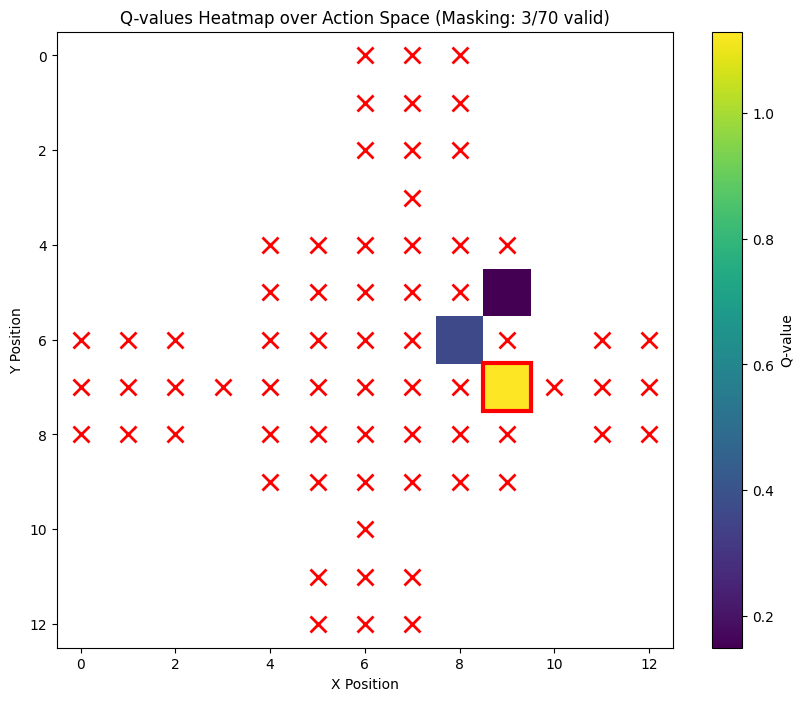

Episode 1 | Total Reward: 5.04 | Steps: 9
Episode 2 | Total Reward: 3.11 | Steps: 19
Episode 3 | Total Reward: 4.00 | Steps: 8
Episode 4 | Total Reward: 5.00 | Steps: 9
Episode 5 | Total Reward: 4.02 | Steps: 14


In [7]:
# Load trained agent
loaded_agent = DRQNagent.load_complete(
    'models/DRQN_actionmask.pkl',  # Change to your model path
    env_constructor=lambda: VoltageDistributionEnv(),
    feature_extractor_constructor=lambda obs_space: CustomFeatureExtractor(obs_space)
)

# Run visualization
# Set use_action_masking=True if model was trained with action_mask=True
main(loaded_agent, episodes=5, render_delay=0.1, use_action_masking=True)